# I-V Map

2025/8/1

data 20250730


In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial']
import h5py
import os

# from module
from h5utils import HDF5Analyzer

In [22]:
subpath1 = "map1"

h5_dark_path = os.path.join(root_path, subpath1, "ivmapsing.h5")
darkh5 = HDF5Analyzer(h5_dark_path)
darkh5.list_h5_struct()


--- Listing all groups and datasets in '/home/tim/Documents/AS/data/nanonis2/20250730/map1/ivmapsing.h5' by traversing the hierarchy ---
GROUP: /data/
    DATASET: /data/bias (Shape: (478,), Dtype: float64)
    DATASET: /data/current_fwd (Shape: (478, 4900), Dtype: float64)
GROUP: /scanpixels/
    DATASET: /scanpixels/values (Shape: (2,), Dtype: int32)
GROUP: /scanrange/
  - ATTRIBUTE: 'unit' = 'b'm''
    DATASET: /scanrange/values (Shape: (2,), Dtype: float64)


In [23]:
darkh5.build_struct_dict()
darkh5.h5struct

--- Building a Python dictionary from HDF5 file '/home/tim/Documents/AS/data/nanonis2/20250730/map1/ivmapsing.h5' ---

Successfully built the structured dictionary. File is now closed.
An error occurred: name 'h5_structure_dict' is not defined


{'_attributes': {'ExpDate': b'30.07.2025'},
 'data': {'bias': {'type': 'dataset',
   'shape': (478,),
   'dtype': 'float64',
   'path': '/data/bias',
   'data': array([-0.0603    , -0.06004717, -0.05979434, -0.05954151, -0.05928868,
          -0.05903585, -0.05878302, -0.05853019, -0.05827736, -0.05802453,
          -0.0577717 , -0.05751887, -0.05726604, -0.05701321, -0.05676038,
          -0.05650755, -0.05625472, -0.05600189, -0.05574906, -0.05549623,
          -0.0552434 , -0.05499057, -0.05473774, -0.0544849 , -0.05423208,
          -0.05397924, -0.05372642, -0.05347358, -0.05322076, -0.05296792,
          -0.05271509, -0.05246227, -0.05220943, -0.05195661, -0.05170377,
          -0.05145094, -0.05119811, -0.05094528, -0.05069245, -0.05043962,
          -0.05018679, -0.04993396, -0.04968114, -0.0494283 , -0.04917547,
          -0.04892264, -0.04866981, -0.04841698, -0.04816415, -0.04791132,
          -0.04765849, -0.04740566, -0.04715283, -0.0469    , -0.04664717,
          -0.0463

In [24]:
bias = darkh5.h5struct['data']['bias']['data']
darkcurrent_map = darkh5.h5struct['data']['current_fwd']['data']
unit = darkh5.h5struct['scanrange']['_attributes']['unit'].decode('utf-8')
pixels = darkh5.h5struct['scanpixels']['values']['data']
scanrange = darkh5.h5struct['scanrange']['values']['data']
pixel_size = scanrange[0]/pixels[0]
pixel_size

7.143028571428573e-09

Bias sliced at index 477, bias = 0.0603
/home/tim/Documents/AS/data/nanonis2/20250730/map1/ivmapsing_map_curves_matplot.png


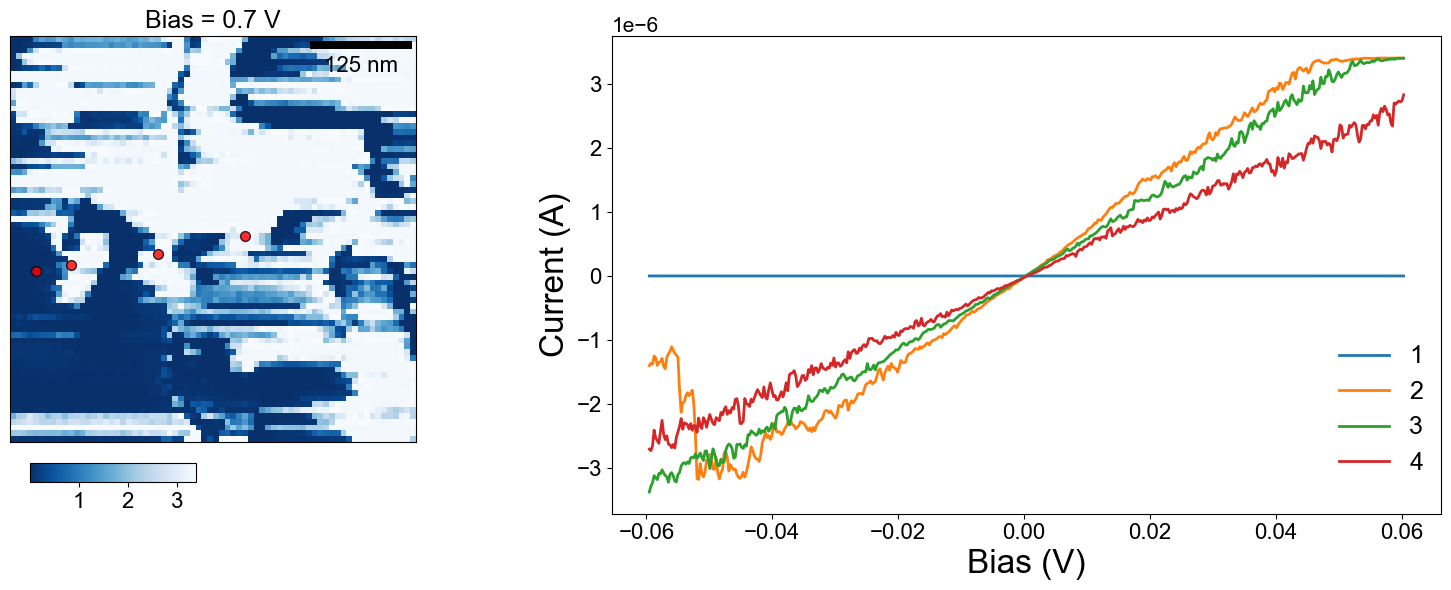

In [33]:

fig, ax = plt.subplots(1,2, figsize = (17,6))

bias_slice = 0.7
index = darkh5.get_nearest_index(bias_slice)

data = np.reshape(darkcurrent_map[index,:] *1e6, pixels)

heatmap = ax[0].imshow(data,
                    aspect='equal',
                    origin='lower',
                    cmap = 'Blues_r')

cbar = fig.colorbar(heatmap, ax=ax[0], orientation='horizontal',
                    pad=0,
                    aspect = 9,
                    shrink=0.2,
                    anchor=(0.35, 0.6)
                   )

cbar.ax.tick_params(labelsize=16)

x0_list = [4, 10, 25, 40]
y0_list = [29, 30, 32, 35]

ax[0].scatter(x0_list, y0_list,
            c = 'red',
            s=50,                 
            marker='o',             
            edgecolors='black',     
            alpha=0.8,              
            label='')

position_index_list = [darkh5.get_position_index(x, y) for x, y in zip(x0_list, y0_list)]

ax[0].set_xticks([]) 
ax[0].set_yticks([]) 
ax[0].set_title(f"Bias = {bias_slice} V", fontsize = 18)

pixel_size_in_nanometers = pixel_size*1e9

scalebar = ScaleBar(pixel_size_in_nanometers, 'nm',
                    length_fraction=0.25, 
                    height_fraction=0.02, 
                    location='upper right', # Position (e.g., 'lower right', 'upper left')
                    box_color='white', 
                    box_alpha=0, 
                    color='black', 
                    font_properties={'size': 16}) 

ax[0].add_artist(scalebar)

islogy = False

for (i, p_idx) in enumerate(position_index_list):
    y_values = darkcurrent_map[3:, p_idx] 

    if islogy:
        ax[1].plot(bias[3:], np.abs(y_values), lw=2, label=f'{i+1}')
    else:
        ax[1].plot(bias[3:], y_values, lw=2, label=f'{i+1}')

ax[1].set_xlabel("Bias (V)", fontsize = 24)
ax[1].set_ylabel("Current (A)", fontsize = 24)

if islogy: 
    ax[1].set_yscale('log')
else:
    ax[1].yaxis.get_offset_text().set_fontsize(15) # order on top of y axis
    
#ax[1].set_ylim(1e-13,1e-7)
ax[1].tick_params(axis='both', labelsize=16) 
ax[1].legend(fontsize=18,
             loc='upper left',
             bbox_to_anchor=(0.85, 0.6) if islogy else (0.85, 0.4),
             frameon=False)
    
output_filename = "{}_map_curves{}_matplot.png".format(
    h5_dark_path[0:-3], 
    '_logy' if islogy else ''
)
print(output_filename)

plt.tight_layout()
plt.savefig(output_filename, dpi=500, bbox_inches = 'tight')
plt.show()


In [81]:
data[45:,45:].shape

(20, 20)

In [177]:
def plot_heatmap(ax, data, title, fig, orientation='horizontal', cmap = 'viridis'):

    x = np.arange(0, 20, 1)
    y = np.arange(0, 20, 1)
    
    z = data[45:,45:]

    heatmap = ax.pcolormesh(x, y, z, cmap=cmap, shading='auto', edgecolor='black', linewidth=1, antialiased=True)

    ax.set_aspect('equal')
    
    """
    heatmap = ax.imshow(data[35:,35:],
                        aspect='equal',
                        origin='lower',
                        cmap = 'viridis') 
    """    
    ax.set_xticks(np.arange(0, 20, 2)) 
    ax.set_yticks(np.arange(0, 20, 2)) 
    ax.tick_params(axis='both', labelsize=16)
    
    ax.set_title(title, fontsize = 18)

    cbar = fig.colorbar(heatmap, ax=ax, orientation=orientation,
                        pad=0,
                        aspect = 9,
                        shrink=0.4,
                        anchor=(0.1, 0.4)
                       )
    
    cbar.ax.tick_params(labelsize=18)

In [106]:
diffdata.shape

(65, 65)

Bias sliced at index 426, bias = 0.79884207
/home/tim/Documents/AS/data/nanonis2/20250723/map2_1.5u_light/ivmapsing_darklight_compare_matplot.png


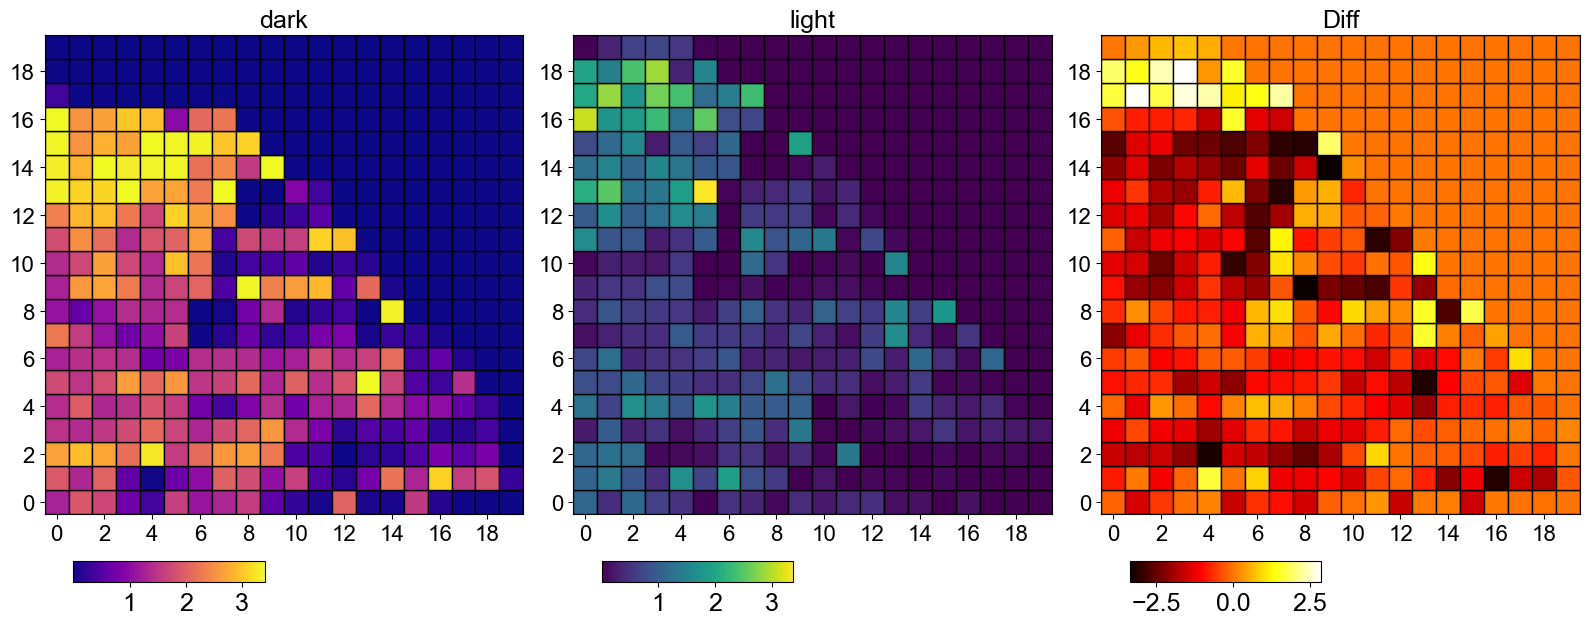

In [180]:

fig, ax = plt.subplots(1,3, figsize = (16, 7))

bias_slice = 0.8
index = lighth5.get_nearest_index(bias_slice)

lightdata = np.reshape(lightcurrent_map[index,:] *1e6, pixels)

darkdata = np.reshape(darkcurrent_map[index,:] *1e6, pixels)

diffdata = np.reshape(lightdata - darkdata, pixels)

plot_heatmap(ax[0], darkdata, 'dark', fig, cmap = 'plasma')

plot_heatmap(ax[1], lightdata, 'light', fig)

plot_heatmap(ax[2], diffdata, 'Diff', fig, cmap = 'hot')

output_filename = h5_light_path[0:-3] + "_darklight_compare_matplot.png"
print(output_filename)

plt.tight_layout()
plt.savefig(output_filename, dpi=500, bbox_inches = 'tight')
plt.show()

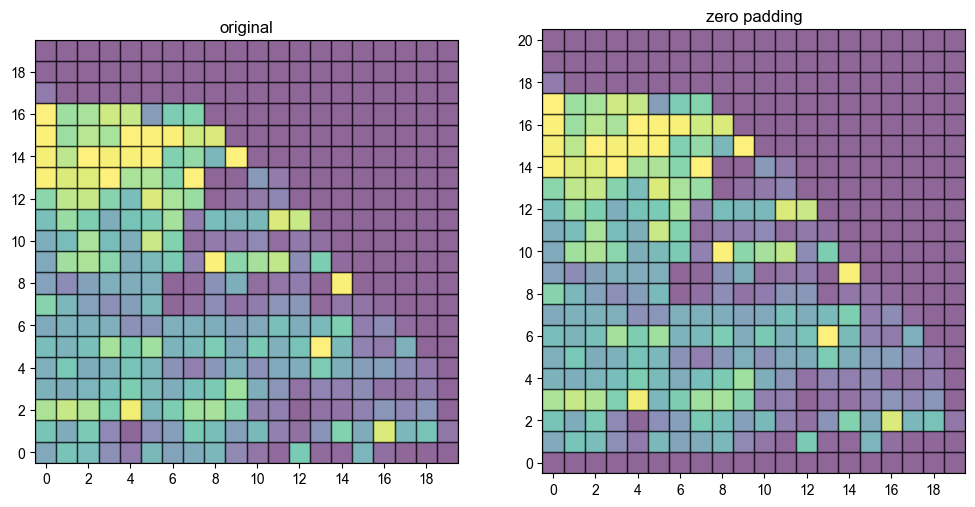

In [275]:

fig, ax = plt.subplots(1,2, figsize = (12, 7))

x1 = np.arange(0, 20, 1)
y1 = np.arange(0, 20, 1)

heatmap1 = ax[0].pcolormesh(x1, y1, darkdata[45:,45:],
                            cmap='viridis',
                            shading='auto',
                            edgecolor='black',
                            alpha=0.6,
                            linewidth=1,
                            antialiased=True)
ax[0].set_xticks(np.arange(0, 20, 2)) 
ax[0].set_yticks(np.arange(0, 20, 2)) 
ax[0].set_aspect('equal')
ax[0].set_title('original')

x2 = np.arange(0, 20, 1)
y2 = np.arange(0, 21, 1)

darkdata_padded = np.pad(darkdata[45:,45:], ((1,0), (0, 0)), mode='constant', constant_values=0)

heatmap2 = ax[1].pcolormesh(x2, y2, darkdata_padded,
                            cmap='viridis',
                            shading='auto',
                            edgecolor='black',
                            alpha=0.6,
                            linewidth=1,
                            antialiased=True)
ax[1].set_xticks(np.arange(0, 20, 2)) 
ax[1].set_yticks(np.arange(0, 22, 2)) 
ax[1].set_aspect('equal')
ax[1].set_title('zero padding')

plt.show()

Bias sliced at index 426, bias = 0.79884207
/home/tim/Documents/AS/data/nanonis2/20250723/map2_1.5u_light/ivmapsing_darklight_compare2_matplot.png


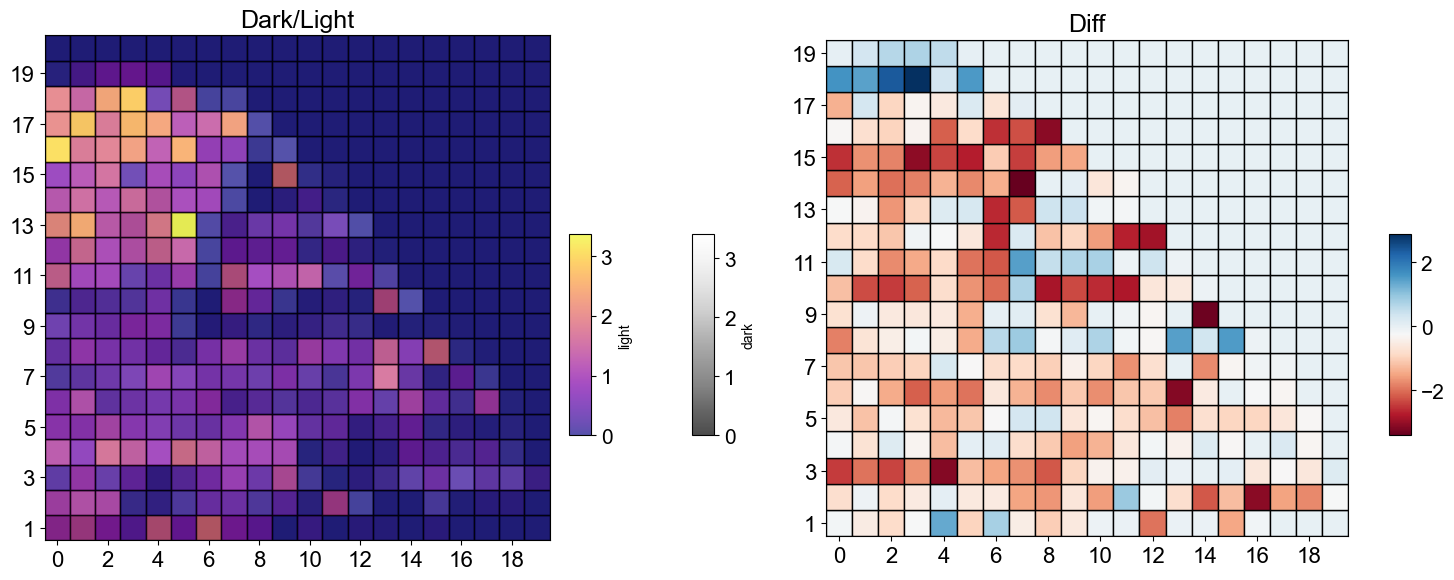

In [293]:

fig, ax = plt.subplots(1,2, figsize = (15, 7), gridspec_kw={'width_ratios': [1.15, 1]})

bias_slice = 0.8
index = lighth5.get_nearest_index(bias_slice)

lightdata = np.reshape(lightcurrent_map[index,:] *1e6, pixels)
lightdata_padded = np.pad(lightdata[45:,45:], ((0, 1), (0, 0)), mode='constant', constant_values=0)

darkdata = np.reshape(darkcurrent_map[index,:] *1e6, pixels)
darkdata_padded = np.pad(darkdata[45:,45:], ((1, 0), (0, 0)), mode='constant', constant_values=0)

diffdata = lightdata_padded - darkdata_padded

x1 = np.arange(0, 20, 1)
y1 = np.arange(1, 21, 1)

heatmap1 = ax[0].pcolormesh(x1, y1, darkdata_padded[:-1,:],
                            cmap='Greys_r',
                            shading='auto',
                            edgecolor='black',
                            alpha=0.7,
                            linewidth=1,
                            antialiased=True)

x2 = np.arange(0, 20, 1)
y2 = np.arange(1, 21, 1)

heatmap2 = ax[0].pcolormesh(x2, y2, lightdata_padded[1:,:],
                            cmap='plasma',
                            shading='auto',
                            edgecolor='black',
                            alpha=0.7,
                            linewidth=1,
                            antialiased=True)

ax[0].set_aspect('equal')
ax[0].set_xticks(np.arange(0, 20, 2)) 
ax[0].set_yticks(np.arange(1, 21, 2)) 
ax[0].tick_params(axis='both', labelsize=16)
ax[0].set_title("Dark/Light", fontsize=18)

cbar1 = fig.colorbar(heatmap1, ax=ax[0], 
                    orientation='vertical',
                    pad=0.04,
                    aspect = 9,
                    shrink=0.3,
                    anchor=(0.1, 0.4))

cbar1.set_label('dark')
cbar1.ax.tick_params(labelsize=15)

cbar2 = fig.colorbar(heatmap2, ax=ax[0], 
                    orientation='vertical',
                    pad=0.02,
                    aspect = 9,
                    shrink=0.3,
                    anchor=(0.1, 0.4))

cbar2.set_label('light')
cbar2.ax.tick_params(labelsize=15)

x3 = np.arange(0, 20, 1)
y3 = np.arange(1, 20, 1)

heatmap3 = ax[1].pcolormesh(x3, y3, diffdata[1:-1,:],
                         cmap='RdBu',
                         shading='auto',
                         edgecolor='black',
                         linewidth=1,
                         antialiased=True)

ax[1].set_aspect('equal')

ax[1].set_xticks(np.arange(0, 20, 2)) 
ax[1].set_yticks(np.arange(1, 21, 2)) 
ax[1].tick_params(axis='both', labelsize=16)

ax[1].set_title("Diff", fontsize = 18)

cbar3 = fig.colorbar(heatmap3, ax=ax[1], orientation='vertical',
                    pad=0.05,
                    aspect = 9,
                    shrink=0.3,
                    anchor=(0.1, 0.4)
                   )
cbar3.ax.tick_params(labelsize=15)

output_filename = h5_light_path[0:-3] + "_darklight_compare2_matplot.png"
print(output_filename)

plt.tight_layout()
plt.savefig(output_filename, dpi=500, bbox_inches = 'tight')

plt.show()

Bias sliced at index 426, bias = 0.79884207
/home/tim/Documents/AS/data/nanonis2/20250723/map2_1.5u_light/ivmapsing_darklight_compare3_matplot.png


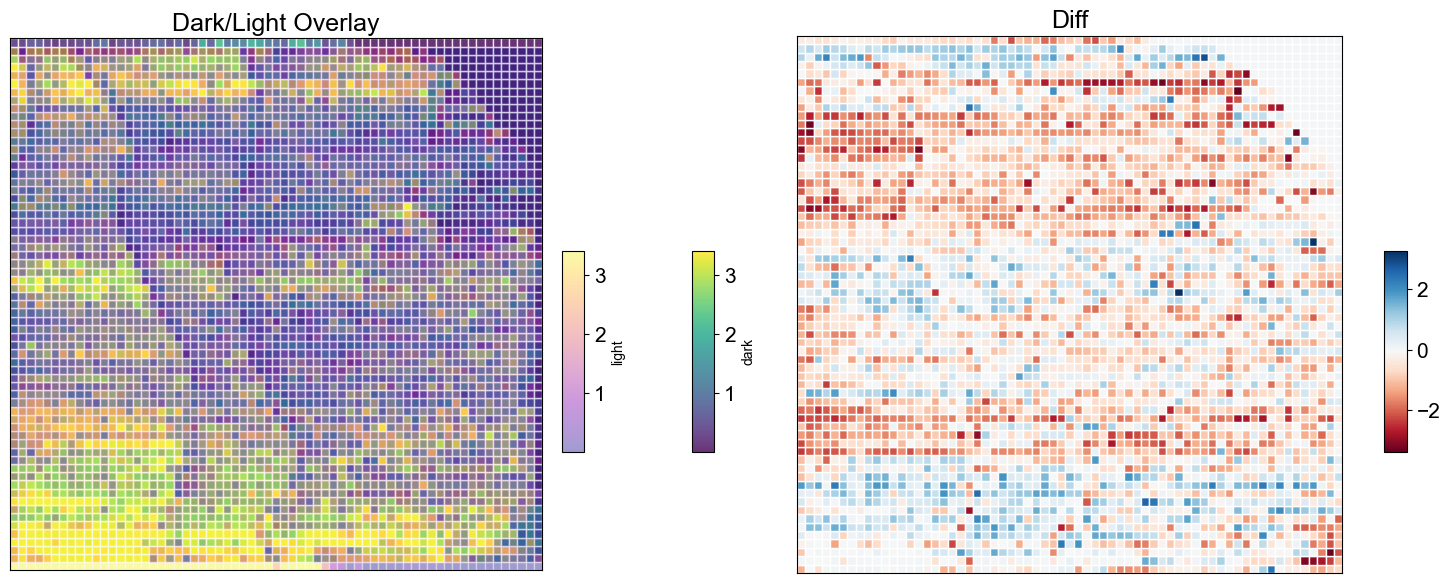

In [297]:

fig, ax = plt.subplots(1,2, figsize = (15, 7), gridspec_kw={'width_ratios': [1.16, 1]})

bias_slice = 0.8
index = lighth5.get_nearest_index(bias_slice)

lightdata = np.reshape(lightcurrent_map[index,:] *1e6, pixels)
lightdata_padded = np.pad(lightdata, ((0, 1), (0, 0)), mode='constant', constant_values=0)

darkdata = np.reshape(darkcurrent_map[index,:] *1e6, pixels)
darkdata_padded = np.pad(darkdata, ((1, 0), (0, 0)), mode='constant', constant_values=0)

diffdata = lightdata_padded - darkdata_padded

x1 = np.arange(0, pixels[0], 1)
y1 = np.arange(2, pixels[1]+1, 1)

heatmap1 = ax[0].pcolormesh(x1, y1, darkdata_padded[2:,:],
                            cmap='viridis',
                            shading='auto',
                            edgecolor='white',
                            alpha=0.8,
                            linewidth=1,
                            antialiased=True)

x2 = np.arange(0, pixels[0], 1)
y2 = np.arange(1, pixels[1], 1)

heatmap2 = ax[0].pcolormesh(x2, y2, lightdata_padded[:-2,:],
                            cmap='plasma',
                            shading='auto',
                            edgecolor='white',
                            alpha=0.4,
                            linewidth=1,
                            antialiased=True)

ax[0].set_aspect('equal')
ax[0].set_xticks([]) 
ax[0].set_yticks([]) 
ax[0].tick_params(axis='both', labelsize=16)
ax[0].set_title("Dark/Light Overlay", fontsize=18)

cbar1 = fig.colorbar(heatmap1, ax=ax[0], 
                    orientation='vertical',
                    pad=0.04,
                    aspect = 9,
                    shrink=0.3,
                    anchor=(0.1, 0.4))

cbar1.set_label('dark')
cbar1.ax.tick_params(labelsize=15)

cbar2 = fig.colorbar(heatmap2, ax=ax[0], 
                    orientation='vertical',
                    pad=0.02,
                    aspect = 9,
                    shrink=0.3,
                    anchor=(0.1, 0.4))

cbar2.set_label('light')
cbar2.ax.tick_params(labelsize=15)

x3 = np.arange(0, pixels[0], 1)
y3 = np.arange(1, pixels[1], 1)

heatmap3 = ax[1].pcolormesh(x3, y3, diffdata[2:,:],
                         cmap='RdBu',
                         shading='auto',
                         edgecolor='white',
                         linewidth=1,
                         antialiased=True)

ax[1].set_aspect('equal')

ax[1].set_xticks([]) 
ax[1].set_yticks([]) 
#ax[1].tick_params(axis='both', labelsize=16)

ax[1].set_title("Diff", fontsize = 18)

cbar3 = fig.colorbar(heatmap3, ax=ax[1], orientation='vertical',
                    pad=0.05,
                    aspect = 9,
                    shrink=0.3,
                    anchor=(0.1, 0.4)
                   )
cbar3.ax.tick_params(labelsize=15)

output_filename = h5_light_path[0:-3] + "_darklight_compare3_matplot.png"
print(output_filename)

plt.tight_layout()
plt.savefig(output_filename, dpi=500, bbox_inches = 'tight')

plt.show()